
# DIABETIC RETINOPATHY DETECTION DATA MINING PROJECT


this project is made by third year data science students at the Lebanese University for the data mining course (fall semester 5 year 25-26)
                Rouba Madani, Hussein Safa



# STEP 1: import libraries and load the data 


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt


In [8]:
#load the data

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
CLASS_NAMES = ["No_DR", "DR"] #makesure 0 is No_DR 1 is DR

train_ds = tf.keras.utils.image_dataset_from_directory(
    "data/train",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "data/valid",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary"
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "data/test",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    label_mode="binary"
)


Found 2076 files belonging to 2 classes.
Found 531 files belonging to 2 classes.
Found 231 files belonging to 2 classes.


In [9]:
#makesure i have my own classes and the data loaded correctly
class_names = train_ds.class_names
print(class_names)


['No_DR', 'DR']


In [10]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.map(lambda x, y: (x / 255.0, y)).prefetch(AUTOTUNE)
val_ds   = val_ds.map(lambda x, y: (x / 255.0, y)).prefetch(AUTOTUNE)
test_ds  = test_ds.map(lambda x, y: (x / 255.0, y)).prefetch(AUTOTUNE)

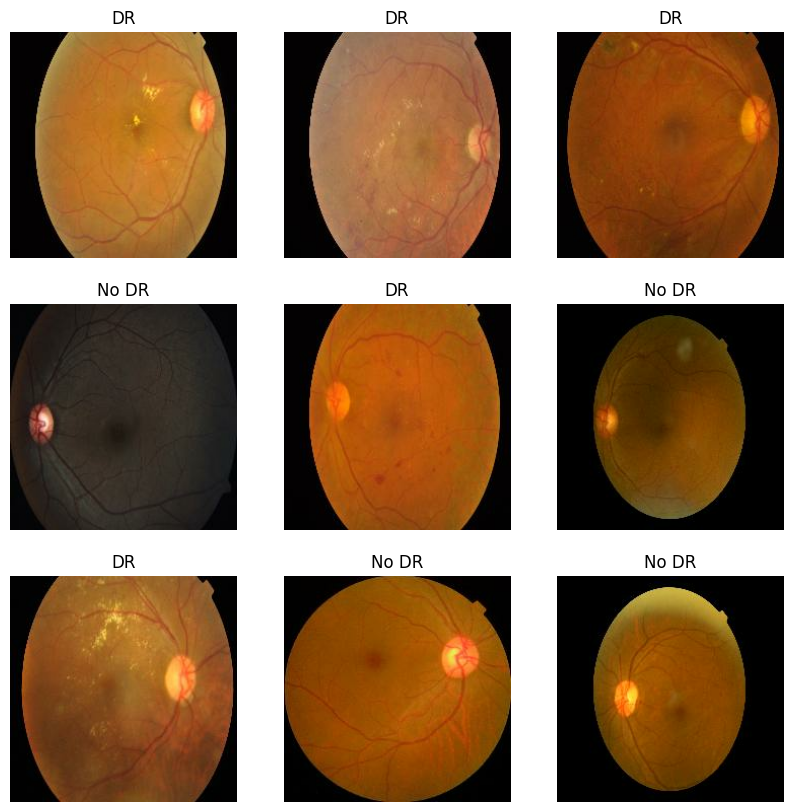

In [11]:
#check if my images are the same
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title("DR" if labels[i] == 1 else "No DR")
        plt.axis("off")


# STEP 2: create the baseline cnn


In [14]:
from tensorflow.keras import layers, models

In [15]:
#randomize the data to better generalize
data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [16]:
#create our model using 3 layers and working on our dense layer
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')  
])


In [17]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)
# compile the model add the metrics needed to makesure the model is learning when training

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 222, 222, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 111, 111, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 109, 109, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 54, 54, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 52, 52, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 26, 26, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 86528)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      11,075,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=3
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)
#the callbacks are to monitor the training of the model so that we dont run into overfitting problems

Epoch 1/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 39s 570ms/step - accuracy: 0.6859 - auc: 0.7578 - loss: 0.5936 - precision: 0.6843 - recall: 0.7038 - val_accuracy: 0.9021 - val_auc: 0.9580 - val_loss: 0.3191 - val_precision: 0.8755 - val_recall: 0.9184 - learning_rate: 1.0000e-04
Epoch 2/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 40s 610ms/step - accuracy: 0.8492 - auc: 0.9240 - loss: 0.3648 - precision: 0.8422 - recall: 0.8638 - val_accuracy: 0.9040 - val_auc: 0.9661 - val_loss: 0.2384 - val_precision: 0.8911 - val_recall: 0.9020 - learning_rate: 1.0000e-04
Epoch 3/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 38s 580ms/step - accuracy: 0.8863 - auc: 0.9433 - loss: 0.3088 - precision: 0.8951 - recall: 0.8781 - val_accuracy: 0.8851 - val_auc: 0.9661 - val_loss: 0.2491 - val_precision: 0.8309 - val_recall: 0.9429 - learning_rate: 1.0000e-04
Epoch 4/30
65/65 ━━━━━━━━━━━━━━━━━━━━ 35s 540ms/step - accuracy: 0.8839 - auc: 0.9509 - loss: 0.2841 - precision: 0.8878 - recall: 0.8819 - val_accuracy: 0.9209 - val_auc: 0.9673 - val_lo

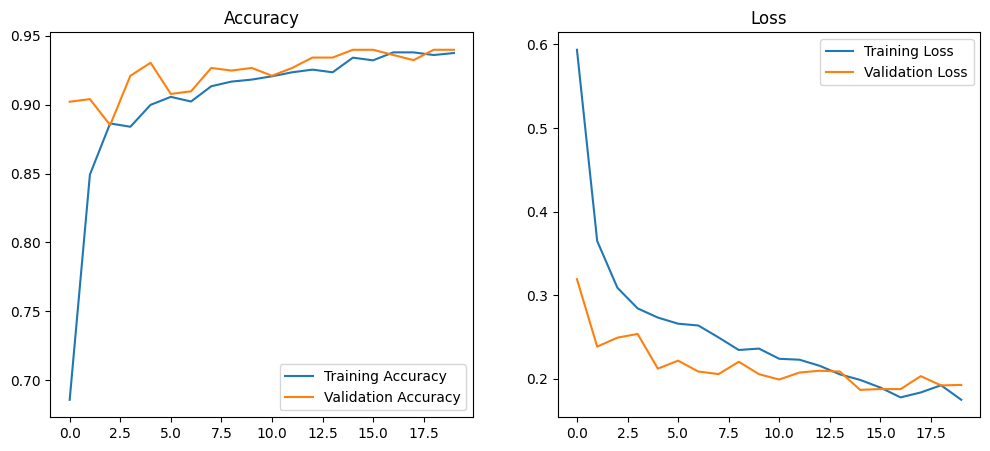

In [19]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend()
plt.title('Loss')

plt.show()



# STEP 3: evaluate the model on testing data


In [20]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_true.extend(labels.numpy())
    y_pred.extend((preds > 0.5).astype(int).flatten())

y_true = np.array(y_true)
y_pred = np.array(y_pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step



# STEP 4: know the metrics and evaluate the model


In [21]:
from sklearn.metrics import classification_report, confusion_matrix

print(confusion_matrix(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=["No DR", "DR"]))


[[111   7]
 [  7 106]]
              precision    recall  f1-score   support

       No DR       0.94      0.94      0.94       118
          DR       0.94      0.94      0.94       113

    accuracy                           0.94       231
   macro avg       0.94      0.94      0.94       231
weighted avg       0.94      0.94      0.94       231



In [22]:
from sklearn.metrics import roc_auc_score

y_prob = []

for images, labels in test_ds:
    preds = model.predict(images)
    y_prob.extend(preds.flatten())

roc_auc = roc_auc_score(y_true, y_prob)
print("ROC-AUC:", roc_auc)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
ROC-AUC: 0.9775011249437527



# STEP 5: save the model


In [23]:
model.save("diabetic_retinopathy_cnn.keras")